**About:** Cell Tracking — TemporalUNet3D + SimpleNodeTransformer Inference

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd ../src

/data/kaggle-cell-tracking/src


In [3]:
import os
import cv2
import glob
import json
import torch
import zarr
import warnings
import polars as pl
import numpy as np
import pandas as pd
import tracksdata as td
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore", category=UserWarning)

In [4]:
from tracking.plot import plot_detection, plot_edges, plot_sample
from utils.plot import plot_contours, scatter_plot_center_preds

from utils.metrics import match_frame_nodes
from tracking.post_process import build_graph
from tracking_cellmot.metrics import evaluate, node_recall, per_sample_metrics, summarise

from tracking.predict import predict_video

from utils.logger import Config
from tracking.main import build_model

In [5]:
from params import TRAIN_DIR, LOG_FOLDER, SCALE

TRAIN_DIR = Path(TRAIN_DIR)
LOG_FOLDER = Path(LOG_FOLDER)

WINDOW_SIZE = 2

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


### Model

In [100]:
LOG_FOLDER = "../logs/2026-08-18/35/"  # new seg
LOG_FOLDER = "../logs/2026-08-19/2/"  # full res seg + frozen unet
LOG_FOLDER = "../logs/2026-08-19/5/"  # full res seg + frozen unet + geom fts

FOLD = 0

In [101]:
cfg = Config(json.load(open(LOG_FOLDER + "args.json", "r")))

In [102]:
checkpoints = sorted(glob.glob(LOG_FOLDER + f"fold_{FOLD}/ckpt_*.pt", recursive=True))

if len(checkpoints) > 1:
    checkpoints = [c for c in checkpoints if "pretrain" not in c]
if checkpoints:
    ckpt_path = checkpoints[-1]
    print(f"Loading: {ckpt_path}")
else:
    ckpt_path = None
    print("No checkpoint found — run train_track.sh first.")

Loading: ../logs/2026-08-19/5/fold_0/ckpt_final.pt


In [103]:
model = build_model(cfg, None)
model.eval().to(device)

ckpt = torch.load(ckpt_path)
state = ckpt.get("model_state_dict", ckpt)
model.load_state_dict(state, strict=True)

<All keys matched successfully>

### Data

In [104]:
from tracking.main import _paths_for_embryos

paths = _paths_for_embryos(TRAIN_DIR, "44b6")
paths[0]

PosixPath('../input/train/44b6_0113de3b')

In [105]:
# sample_name = "6bba_09961292"
sample_name = "44b6_0113de3b"
# sample_name = "6bba_05b6850b"
sample_name = "44b6_0b24845f"

In [106]:
df = pd.read_csv(f"../input/metadata.csv")
n_total = df[df['sample_name'] == sample_name]["estimated_number_of_nodes"].values[0]
print(f"Estimated number of nodes: {n_total}")

Estimated number of nodes: 32795


In [107]:
tracks_path = TRAIN_DIR / f"{sample_name}.geff"
result = td.graph.IndexedRXGraph.from_geff(tracks_path)
gt_graph = result[0] if isinstance(result, tuple) else result

node_attrs = gt_graph.node_attrs()

In [108]:
vol = zarr.open_group(str(TRAIN_DIR / f'{sample_name}.zarr'), mode="r")["0"]

### Predict

In [123]:
class PredictConfig:
    det_tta = False

    # --- Nodes ---
    nms = "greedy"
    nms_radius_um = 7.0
    det_threshold = 0.25
    pool_kernel_um = 5.0
    edge_activation = "softmax"

    # --- Edges ---
    edge_selection = "argmax"
    edge_threshold = 0.
    
    max_parents_per_node = 1
    max_children_per_node = 2

In [124]:
coords, edges, det_logits = predict_video(
    model,
    TRAIN_DIR / sample_name,
    device=device,
    cfg=PredictConfig,
    window_size=WINDOW_SIZE,
    downscale_factor=cfg.downscale_factor,
    max_frames=100,
)

# coords: (N, 4) [t, z, y, x] in ORIGINAL resolution
# edges:  list of (src_idx, tgt_idx, prob, distance) indexing rows of coords

In [125]:
print(f"- Found {coords.shape[0]} nodes & {len(edges)} edges")
print(f"- Estimated number of nodes: {n_total}")

- Found 47672 nodes & 47220 edges
- Estimated number of nodes: 32795


In [126]:
graph = build_graph(coords, edges)

res = evaluate(graph, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")


- Node recall: 0.980
- edge_tp: 44
- edge_fp: 9
- edge_fn: 5
- edge_jaccard: 0.759
- adj_edge_jaccard: 0.724
- division_jaccard: 0.000
- score: 0.724


#### Plot nodes

-> Matched 1 out of 1 GT nodes at frame 11
-> Matched 1 out of 1 GT nodes at frame 12
-> Matched 1 out of 1 GT nodes at frame 13
-> Matched 1 out of 1 GT nodes at frame 14
-> Matched 1 out of 1 GT nodes at frame 15
-> Matched 1 out of 1 GT nodes at frame 16
-> Matched 1 out of 1 GT nodes at frame 17
-> Matched 1 out of 1 GT nodes at frame 18
-> Matched 1 out of 1 GT nodes at frame 19
-> Matched 1 out of 1 GT nodes at frame 20
-> Matched 1 out of 1 GT nodes at frame 21
-> Matched 1 out of 1 GT nodes at frame 22
-> Matched 1 out of 1 GT nodes at frame 23
-> Matched 1 out of 1 GT nodes at frame 24
-> Matched 1 out of 1 GT nodes at frame 25
-> Matched 1 out of 1 GT nodes at frame 26
-> Matched 1 out of 1 GT nodes at frame 27
-> Matched 1 out of 1 GT nodes at frame 28
-> Matched 1 out of 1 GT nodes at frame 29
-> Matched 1 out of 1 GT nodes at frame 30
-> Matched 1 out of 1 GT nodes at frame 31
-> Matched 1 out of 1 GT nodes at frame 32
-> Matched 1 out of 1 GT nodes at frame 33
-> Matched 

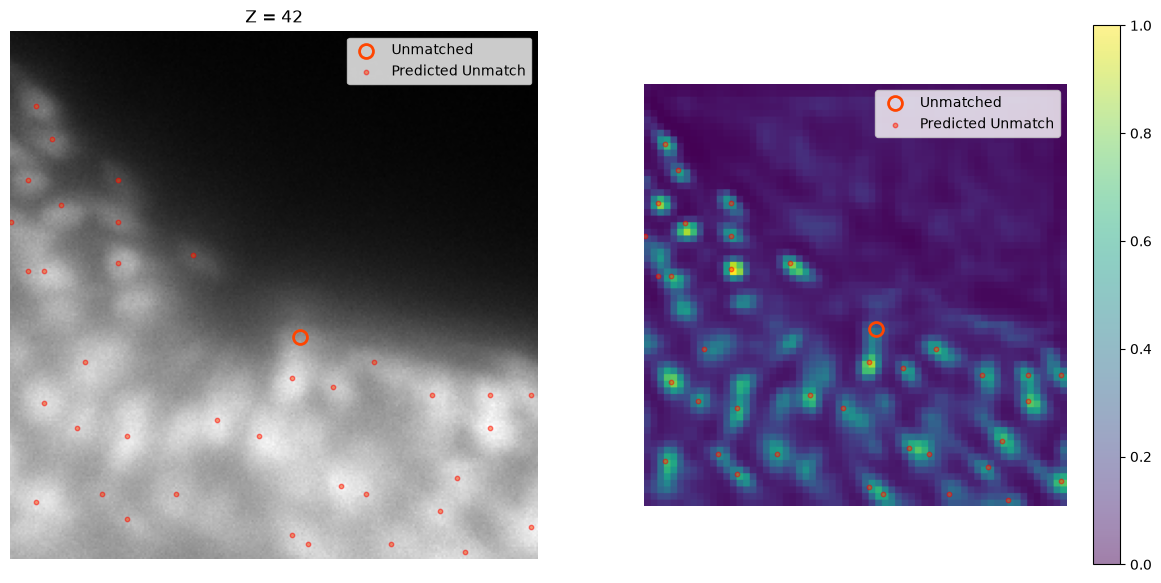

-> Matched 2 out of 2 GT nodes at frame 41
-> Matched 2 out of 2 GT nodes at frame 42
-> Matched 2 out of 2 GT nodes at frame 43
-> Matched 2 out of 2 GT nodes at frame 44
-> Matched 2 out of 2 GT nodes at frame 45
-> Matched 2 out of 2 GT nodes at frame 46
-> Matched 2 out of 2 GT nodes at frame 47
-> Matched 2 out of 2 GT nodes at frame 48
-> Matched 2 out of 2 GT nodes at frame 49
-> Matched 1 out of 1 GT nodes at frame 50


In [127]:
gt_ = node_attrs.to_pandas()

n_plot = 0

for frame in gt_["t"].unique():
    gt = gt_[gt_["t"] == frame][["z", "y", "x"]].values

    preds = coords[coords[:, 0] == frame][:, 1:]

    pairs, matched_gt, unmatched_gt = match_frame_nodes(
        preds,
        gt,
        t=frame,
        scale=SCALE,
        max_distance=7,
    )

    print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes at frame {frame}')

    img = vol[frame]
    ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else [] #np.unique(gt[:, 0])

    if not len(ids):
        continue

    tol = 3

    for i in ids:
        for d in [0]:
            plt.figure(figsize=(15, 7))
            plt.subplot(1, 2, 1)
            plt.title(f"Z = {i + d}")
            plt.imshow(img[i + d], cmap="gray")
            plt.axis("off")
            # break
            scatter_plot_center_preds(preds, matched_gt, unmatched_gt, frame=i + d, tol=tol)
            plt.subplot(1, 2, 2)

            det_logits_ = det_logits[frame][0].squeeze()[(i + d) // cfg.downscale_factor].sigmoid().numpy()
            det_logits_ = cv2.resize(det_logits_, (img.shape[1], img.shape[2]), interpolation=0)
            # det_logits_ = np.where(det_logits_ > PredictConfig.det_threshold, det_logits_, 0)
            plt.imshow(det_logits_)
            scatter_plot_center_preds(preds, matched_gt, unmatched_gt, frame=i + d, tol=tol)
            plt.colorbar()
            plt.axis("off")
            plt.show()
            n_plot += 1

    if n_plot > 3:
        break


### ILP PP

In [128]:
ILD_EDGE_W = -1.0 
ILP_APPEARANCE_W = 0.1 
ILP_DISAPPEARANCE_W = 0.1 
ILP_DIVISION_W = 1.0

In [129]:
%%time
solver = td.solvers.ILPSolver(
    edge_weight=ILD_EDGE_W * td.EdgeAttr("edge_prob"),
    appearance_weight=ILP_APPEARANCE_W,
    disappearance_weight=ILP_DISAPPEARANCE_W,
    division_weight=ILP_DIVISION_W,
)

graph_ilp = solver.solve(graph).detach()

[08/19/26 13:08:04] WARNING  Solver failed with Gurobi, trying Scip.                             ]8;id=10732719;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/solvers/_ilp_solver.py\_ilp_solver.py]8;;\:]8;id=10732720;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/solvers/_ilp_solver.py#363\363]8;;\
                             Got error:                                                                            
                             Gurobi license is not available.                                                      

CPU times: user 15min 9s, sys: 9 s, total: 15min 18s
Wall time: 1min 33s


In [130]:
res = evaluate(graph_ilp, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph_ilp, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

- Node recall: 0.961
- edge_tp: 44
- edge_fp: 1
- edge_fn: 5
- edge_jaccard: 0.880
- adj_edge_jaccard: 0.846
- division_jaccard: nan
- score: 0.846


### More PP

In [131]:
from tracking.pp_public import postprocess_graph

Failed to reload module 'tracking.train' from file '/data/kaggle-cell-tracking/src/tracking/train.py'
Traceback (most recent call last):
  File "/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
  File "/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 584, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/importlib/__init__.py", line 131, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 866, in _exec
  File "<frozen importlib._bootstrap_external>", line 995, in exec_module
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  File "/data/kaggle-cell-tracking/src/tracking/train.py", line 16, in <module>
    from tracking.fit_utils import (
ImportError: cannot import name 'fts_cache_dir' from 'tracking.fit_utils

In [132]:
%%time
nodes_pp, edges_pp, filter_stats = postprocess_graph(graph_ilp, dataset=sample_name)

CPU times: user 33 s, sys: 62.2 ms, total: 33 s
Wall time: 33 s


In [133]:
id_mapping = {n['node_id']: i for i, n in enumerate(nodes_pp)}
nodes_pp = [[n['t'], n['z'], n['y'], n['x']] for n in nodes_pp]
nodes_pp = np.array(nodes_pp)

edges_pp_ = [(id_mapping[e['source_id']], id_mapping[e['target_id']], e['edge_prob'], e['distance_um']) for e in edges_pp]

In [134]:
print(f'Post processed graph: {len(nodes_pp)} nodes (estimated {n_total}) & {len(edges_pp_)} edges')

Post processed graph: 46684 nodes (estimated 32795) & 43484 edges


In [135]:
graph_pp = build_graph(nodes_pp, edges_pp_)

In [136]:
res = evaluate(graph_pp, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph_pp, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

n_total = df[df['sample_name'] == sample_name]["estimated_number_of_nodes"].values[0]
print(f"- Estimated number of nodes: {n_total}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

- Node recall: 1.000
- Estimated number of nodes: 32795
- edge_tp: 48
- edge_fp: 2
- edge_fn: 1
- edge_jaccard: 0.941
- adj_edge_jaccard: 0.901
- division_jaccard: nan
- score: 0.901


### Plots

In [ ]:
from utils.build_graph import build_graph
from utils.plot import plot_trajectory

from tracking_cellmot.metrics import evaluate, per_sample_metrics, node_recall, summarise

In [ ]:
from utils.plot import (
    link_errors,
    error_report,
    plot_error_summary,
    plot_error_map,
    plot_error_neighbourhood,
    plot_trajectory_errors
)


In [ ]:
node_ids = plot_trajectory(gt_graph, root=38000000003)     # a specific starting cell

In [ ]:
# One row per ground-truth edge, saying what we did with it. Needs the graph to
# have been matched, which the evaluate call above did.
errors = link_errors(graph_pp, gt_graph, scale=SCALE)
display(error_report(errors))

plot_error_summary(errors)

In [ ]:
# The frame that went worst, then the single link we lost by the widest margin.
# Swap the query for kind == 'no link' to look at the parents we left childless.
worst_frame = errors[errors["kind"] != "correct"]["t"].value_counts().idxmax()
worst_link = errors.query("kind == 'wrong partner'").sort_values("margin").iloc[0]

plt.figure(figsize=(9, 9))
plot_error_map(graph_pp, errors, t=worst_frame)

plot_error_neighbourhood(graph_pp, worst_link, radius=10.0)

Done !